# 用户行为与会话漏斗

**业务问题：** 从浏览到购买的同一会话有序转化是多少？重复事件会怎样影响指标？

> 本项目使用仓库内的合成教学数据，不代表真实企业业绩。笔记本复用同目录分析模块，确保脚本、结果表与图表口径一致。请使用 Python 3.11 并从仓库内部启动 Jupyter。

## 1. 读取数据

根据当前目录向上定位仓库，不在 notebook 中依赖 `__file__`，也不硬编码电脑路径。

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

# Works when Jupyter starts at the repo root, project directory or notebook directory.
start = Path.cwd().resolve()
root = next((p for p in (start, *start.parents)
             if (p / 'projects' / 'user-behavior-analysis' / 'scripts' / 'analyze.py').is_file()), None)
if root is None:
    raise FileNotFoundError('请在本仓库内启动 Jupyter，或先切换到仓库根目录。')
project_dir = root / 'projects' / 'user-behavior-analysis'
module_path = project_dir / 'scripts' / 'analyze.py'
spec = importlib.util.spec_from_file_location('user_behavior_analysis', module_path)
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
df = analysis.load_data()
assert not df.empty
print('Input rows:', len(df))
display(df.head())


Input rows: 35


,user_id,event_type,event_time,device,region,session_id
0,U001,page_view,2024-01-05 09:15:00,Mobile,East,S001
1,U001,add_to_cart,2024-01-05 09:22:10,Mobile,East,S001
2,U001,checkout,2024-01-05 09:35:20,Mobile,East,S001
3,U001,purchase,2024-01-05 09:48:05,Mobile,East,S001
4,U002,page_view,2024-01-05 10:00:00,Desktop,West,S002


## 2. 数据质量检查

报告缺失与整行重复。重复事件可能是真实行为，不应未经业务判断直接删除。分析模块进一步校验必要字段和数值范围。

In [2]:
display(df.isna().sum().to_frame('missing_count'))
print('Exact duplicate rows:', int(df.duplicated().sum()))

,missing_count
user_id,0
event_type,0
event_time,0
device,0
region,0
session_id,0


Exact duplicate rows: 0


## 3. 指标定义与独立复算

业务漏斗按同一 session_id 内的时间顺序依次匹配 page_view → add_to_cart → checkout → purchase，每个阶段每个会话最多计一次。下方事件覆盖表仅用于对照，不是有序漏斗。

In [3]:
event_coverage = df.groupby('event_type', sort=True).agg(
    event_count=('session_id', 'size'),
    unique_sessions=('session_id', 'nunique'),
    unique_users=('user_id', 'nunique'),
)
display(event_coverage)
print('Distinct sessions:', df['session_id'].nunique())
print('Distinct users:', df['user_id'].nunique())

,event_count,unique_sessions,unique_users
event_type,,,
add_to_cart,10,9,9
checkout,7,7,7
page_view,13,10,10
purchase,5,5,5


Distinct sessions: 10
Distinct users: 10


## 4. 完整分析结果

下面调用可复用的 `analyze(df)`，展示结果表；业务口径详见相邻项目说明和脚本。

In [4]:
results = analysis.analyze(df)
assert isinstance(results, dict) and results
for name, table in results.items():
    print(f'--- {name} ---')
    with pd.option_context('display.max_rows', 50, 'display.max_columns', 20):
        display(table)

--- overview ---


,input_event_rows,deduplicated_events,exact_duplicates_removed,unique_users,sessions,entry_sessions,completed_purchase_sessions
0,35,35,0,10,10,10,5


--- funnel_analysis ---


,stage,sessions,eligible_sessions,step_conversion_pct,entry_conversion_pct
0,page_view,10,10,100.000000,100.0
1,add_to_cart,9,10,90.000000,90.0
2,checkout,7,9,77.777778,70.0
3,purchase,5,7,71.428571,50.0


--- device_conversion ---


...

,session_id,user_id,device,region,event_count,observed_start,observed_end,duration_minutes
0,S001,U001,Mobile,East,4,2024-01-05 09:15:00,2024-01-05 09:48:05,33.083333
1,S002,U002,Desktop,West,3,2024-01-05 10:00:00,2024-01-05 10:15:00,15.000000
2,S003,U003,Mobile,North,6,2024-01-06 14:30:00,2024-01-06 15:35:00,65.000000
3,S004,U004,Desktop,South,2,2024-01-07 11:00:00,2024-01-07 11:05:00,5.000000
4,S005,U005,Mobile,East,4,2024-01-08 13:45:00,2024-01-08 14:15:00,30.000000
5,S006,U006,Desktop,West,5,2024-01-09 09:00:00,2024-01-09 09:55:00,55.000000
6,S007,U007,Mobile,North,1,2024-01-10 16:20:00,2024-01-10 16:20:00,0.000000
7,S008,U008,Desktop,South,4,2024-01-11 10:30:00,2024-01-11 11:00:00,30.000000
8,S009,U009,Mobile,East,2,2024-01-12 08:00:00,2024-01-12 08:10:00,10.000000
9,S010,U010,Desktop,West,4,2024-01-13 14:00:00,2024-01-13 14:25:00,25.000000


--- session_matches ---


,session_id,user_id,device,region,event_count,observed_start,observed_end,duration_minutes,page_view,add_to_cart,checkout,purchase
0,S001,U001,Mobile,East,4,2024-01-05 09:15:00,2024-01-05 09:48:05,33.083333,True,True,True,True
1,S002,U002,Desktop,West,3,2024-01-05 10:00:00,2024-01-05 10:15:00,15.000000,True,True,True,False
2,S003,U003,Mobile,North,6,2024-01-06 14:30:00,2024-01-06 15:35:00,65.000000,True,True,True,True
3,S004,U004,Desktop,South,2,2024-01-07 11:00:00,2024-01-07 11:05:00,5.000000,True,True,False,False
4,S005,U005,Mobile,East,4,2024-01-08 13:45:00,2024-01-08 14:15:00,30.000000,True,True,True,True
5,S006,U006,Desktop,West,5,2024-01-09 09:00:00,2024-01-09 09:55:00,55.000000,True,True,True,True
6,S007,U007,Mobile,North,1,2024-01-10 16:20:00,2024-01-10 16:20:00,0.000000,True,False,False,False
7,S008,U008,Desktop,South,4,2024-01-11 10:30:00,2024-01-11 11:00:00,30.000000,True,True,True,True
8,S009,U009,Mobile,East,2,2024-01-12 08:00:00,2024-01-12 08:10:00,10.000000,True,True,False,False
9,S010,U010,Desktop,West,4,2024-01-13 14:00:00,2024-01-13 14:25:00,25.000000,True,True,True,False


--- event_counts ---


,event_type,events
0,add_to_cart,10
1,checkout,7
2,page_view,13
3,purchase,5


## 5. 可视化

图表与脚本使用同一结果字典，不另写一套计算逻辑。

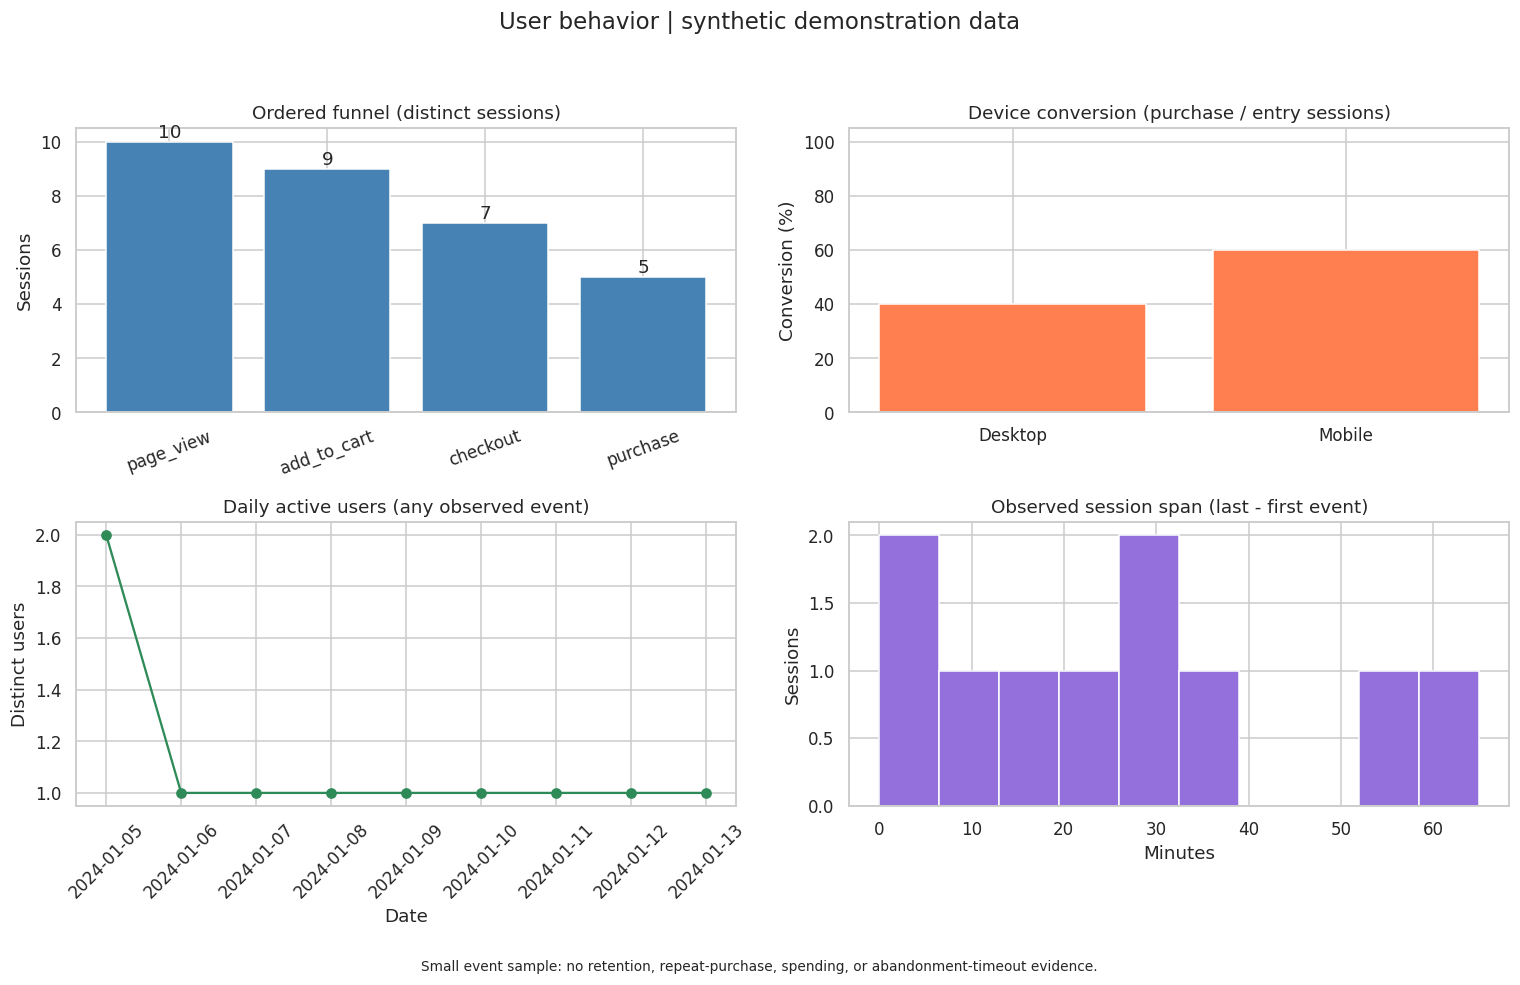

In [5]:
fig = analysis.plot_dashboard(results)
# Explicit PNG display also works with the headless Agg backend.
image = BytesIO()
fig.savefig(image, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image.getvalue()))
plt.close(fig)

## 6. 结论、建议与边界

样本只有 10 个会话、10 位用户。重复浏览或加购不能当作更多用户；应将事件次数与会话漏斗分开报告。没有跨期回访、订单金额或用户注册数据，不能声称已完成留存分析、复购分析或消费能力比较。建议先完善埋点和会话口径，再按设备定位流失环节，并用更大样本验证。

**复现检查：** 从首个代码单元开始运行全部单元；仓库统一验证命令为 `python scripts/validate_portfolio.py`。生成笔记本和实际执行笔记本是两个不同步骤，执行结果以验证报告为准。